<a href="https://colab.research.google.com/github/SUSHMITHA193/Internship-on-Data-Science/blob/main/Week_5_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy scikit-learn

import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("week5_outputs", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
uploaded = files.upload()

# Find the uploaded CSV file
csv_files = [name for name in uploaded.keys()
             if name.lower().endswith(".csv")]

# If a ZIP file was uploaded, extract it
for name in uploaded.keys():
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name, "r") as z:
            z.extractall("week5_dataset")

csv_files += glob.glob("week5_dataset/**/*.csv", recursive=True)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Upload the extracted HR dataset CSV."
    )

# Prefer the IBM HR dataset filename if present
matching = [f for f in csv_files
            if "hr-employee-attrition" in f.lower()]
file_path = matching[0] if matching else csv_files[0]

df = pd.read_csv(file_path)

print("Dataset loaded:", file_path)
print("Dataset shape:", df.shape)
display(df.head())

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Dataset loaded: WA_Fn-UseC_-HR-Employee-Attrition.csv
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

# Clean duplicate records if any
df = df.drop_duplicates().copy()

# Standardize column names by removing extra spaces
df.columns = df.columns.str.strip()

# Validate required target column
if "Attrition" not in df.columns:
    raise ValueError("The dataset must contain an Attrition column.")

# Check target values
print("\nTarget values:", df["Attrition"].unique())

# Remove columns that are constant or identifiers
drop_cols = [
    col for col in
    ["EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"]
    if col in df.columns
]

analysis_df = df.drop(columns=drop_cols).copy()

print("\nShape after removing identifiers/constants:",
      analysis_df.shape)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

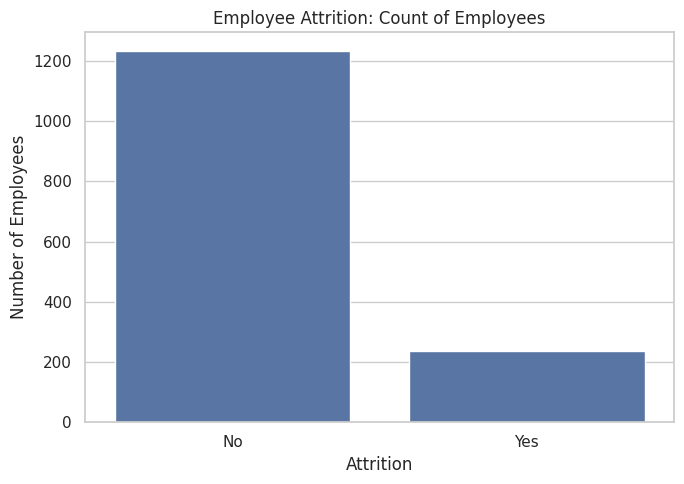

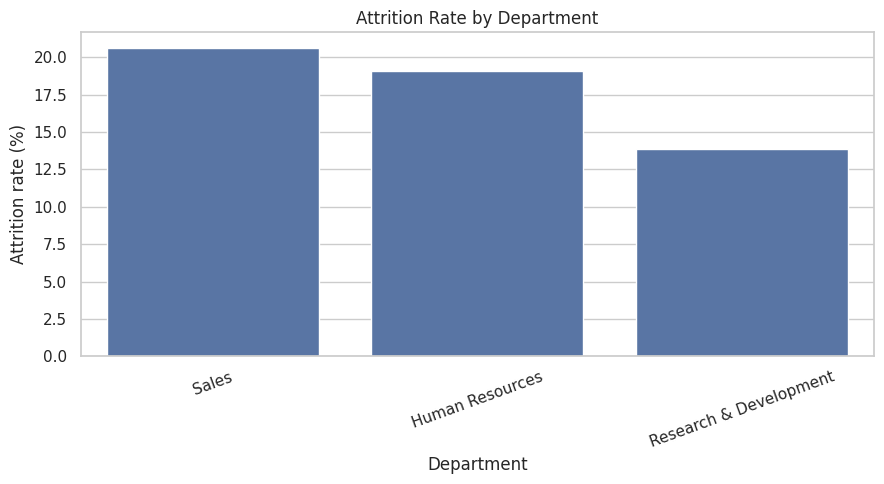

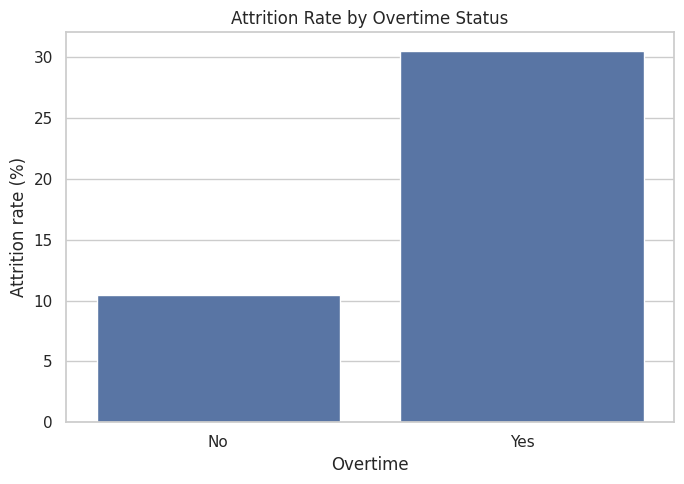

Attrition rate by department (%):


,Attrition rate (%)
Department,
Sales,20.63
Human Resources,19.05
Research & Development,13.84


Attrition rate by overtime (%):


,Attrition rate (%)
OverTime,
No,10.44
Yes,30.53


In [4]:
# Overall attrition counts
attrition_counts = df["Attrition"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=attrition_counts.index,
    y=attrition_counts.values
)
plt.title("Employee Attrition: Count of Employees")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig("week5_outputs/01_attrition_counts.png", dpi=300)
plt.show()

# Attrition rate by department
dept_rate = (
    df.groupby("Department", observed=True)["Attrition"]
      .apply(lambda s: (s == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=dept_rate.index, y=dept_rate.values)
plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("week5_outputs/02_attrition_by_department.png", dpi=300)
plt.show()

# Attrition rate by overtime
overtime_rate = (
    df.groupby("OverTime", observed=True)["Attrition"]
      .apply(lambda s: (s == "Yes").mean() * 100)
)

plt.figure(figsize=(7, 5))
sns.barplot(x=overtime_rate.index, y=overtime_rate.values)
plt.title("Attrition Rate by Overtime Status")
plt.xlabel("Overtime")
plt.ylabel("Attrition rate (%)")
plt.tight_layout()
plt.savefig("week5_outputs/03_attrition_by_overtime.png", dpi=300)
plt.show()

print("Attrition rate by department (%):")
display(dept_rate.round(2).to_frame("Attrition rate (%)"))

print("Attrition rate by overtime (%):")
display(overtime_rate.round(2).to_frame("Attrition rate (%)"))

Mean values by attrition group:


Attrition,No,Yes
JobSatisfaction,2.78,2.47
EnvironmentSatisfaction,2.77,2.46
WorkLifeBalance,2.78,2.66
YearsAtCompany,7.37,5.13
MonthlyIncome,6832.74,4787.09
DistanceFromHome,8.92,10.63


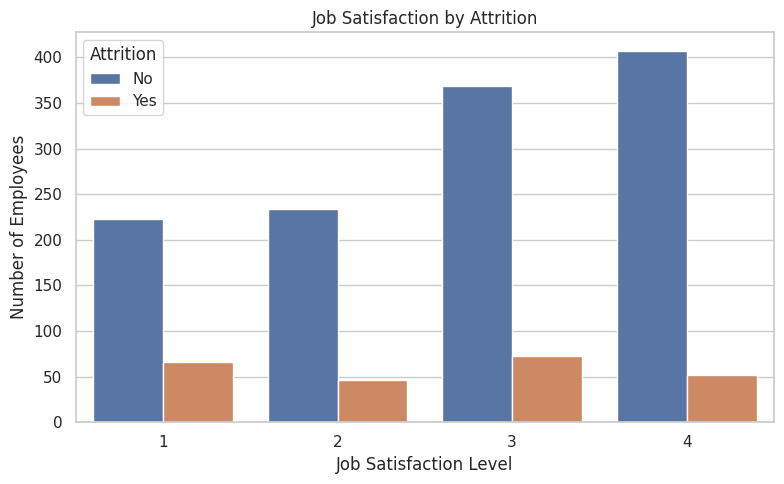

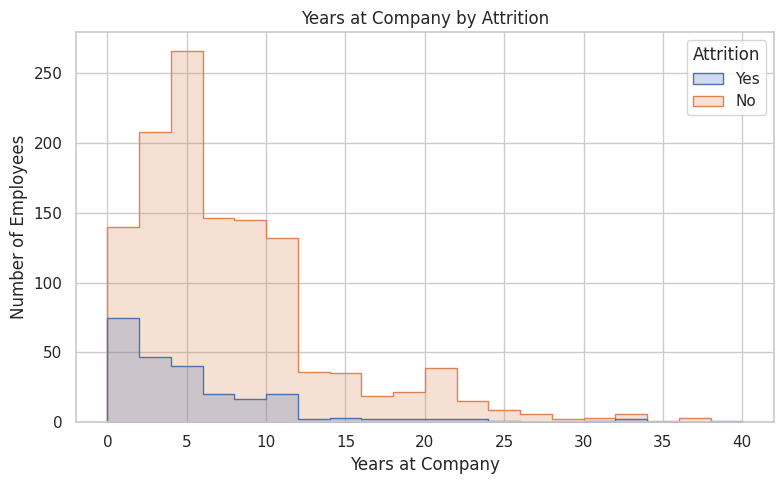

In [5]:
# Compare selected variables between attrition groups
selected_columns = [
    c for c in [
        "JobSatisfaction",
        "EnvironmentSatisfaction",
        "WorkLifeBalance",
        "YearsAtCompany",
        "MonthlyIncome",
        "DistanceFromHome"
    ] if c in df.columns
]

summary = df.groupby("Attrition")[selected_columns].mean().T
print("Mean values by attrition group:")
display(summary.round(2))

# Satisfaction distribution
if "JobSatisfaction" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(
        data=df,
        x="JobSatisfaction",
        hue="Attrition"
    )
    plt.title("Job Satisfaction by Attrition")
    plt.xlabel("Job Satisfaction Level")
    plt.ylabel("Number of Employees")
    plt.tight_layout()
    plt.savefig("week5_outputs/04_job_satisfaction.png", dpi=300)
    plt.show()

# Tenure distribution
if "YearsAtCompany" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x="YearsAtCompany",
        hue="Attrition",
        bins=20,
        multiple="layer",
        element="step"
    )
    plt.title("Years at Company by Attrition")
    plt.xlabel("Years at Company")
    plt.ylabel("Number of Employees")
    plt.tight_layout()
    plt.savefig("week5_outputs/05_tenure_distribution.png", dpi=300)
    plt.show()

In [6]:
contingency = pd.crosstab(df["OverTime"], df["Attrition"])

chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Contingency table:")
display(contingency)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print(
        "Result: There is evidence of an association between "
        "overtime status and attrition in this dataset."
    )
else:
    print(
        "Result: The test did not find statistically significant "
        "evidence of an association in this dataset."
    )

Contingency table:


Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


Chi-square statistic: 87.5643
Degrees of freedom: 1
P-value: 0.000000
Result: There is evidence of an association between overtime status and attrition in this dataset.


In [7]:
# Encode target: Yes = 1, No = 0
X = analysis_df.drop(columns=["Attrition"])
y = (analysis_df["Attrition"] == "Yes").astype(int)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocessing for numeric columns
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model training completed.")

Training samples: 1176
Testing samples: 294
Model training completed.


In [8]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Attrition", "Attrition"],
    zero_division=0
))

metrics_df.to_csv(
    "week5_outputs/model_evaluation_metrics.csv",
    index=False
)

,Metric,Score
0,Accuracy,0.7517
1,Precision,0.3488
2,Recall,0.6383
3,F1-score,0.4511
4,ROC-AUC,0.8032



Classification report:
              precision    recall  f1-score   support

No Attrition       0.92      0.77      0.84       247
   Attrition       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



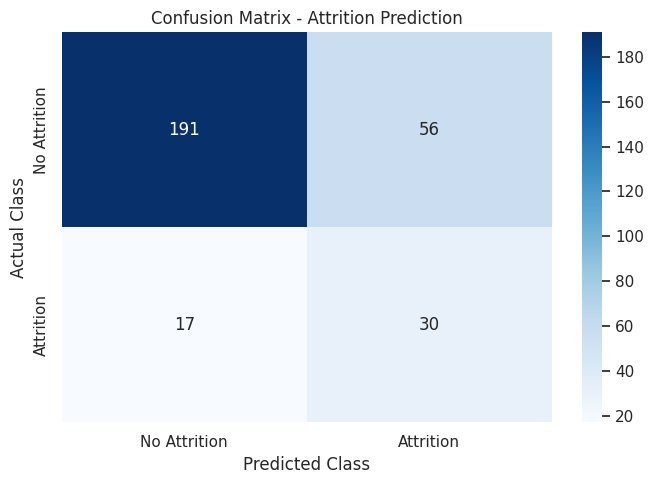

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"]
)
plt.title("Confusion Matrix - Attrition Prediction")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("week5_outputs/06_confusion_matrix.png", dpi=300)
plt.show()

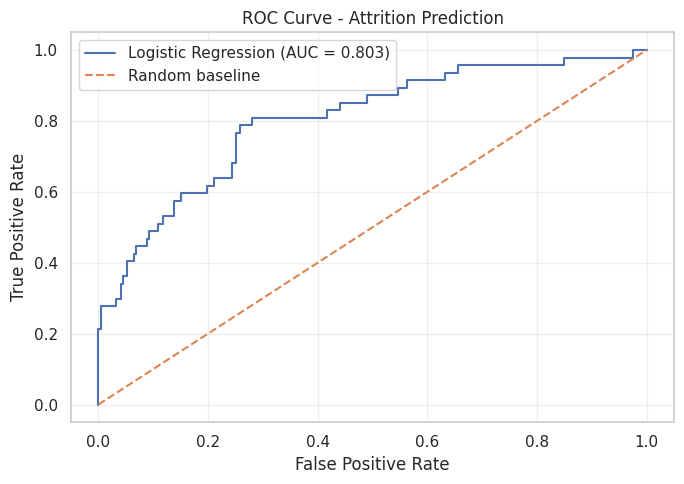

In [10]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Attrition Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("week5_outputs/07_roc_curve.png", dpi=300)
plt.show()

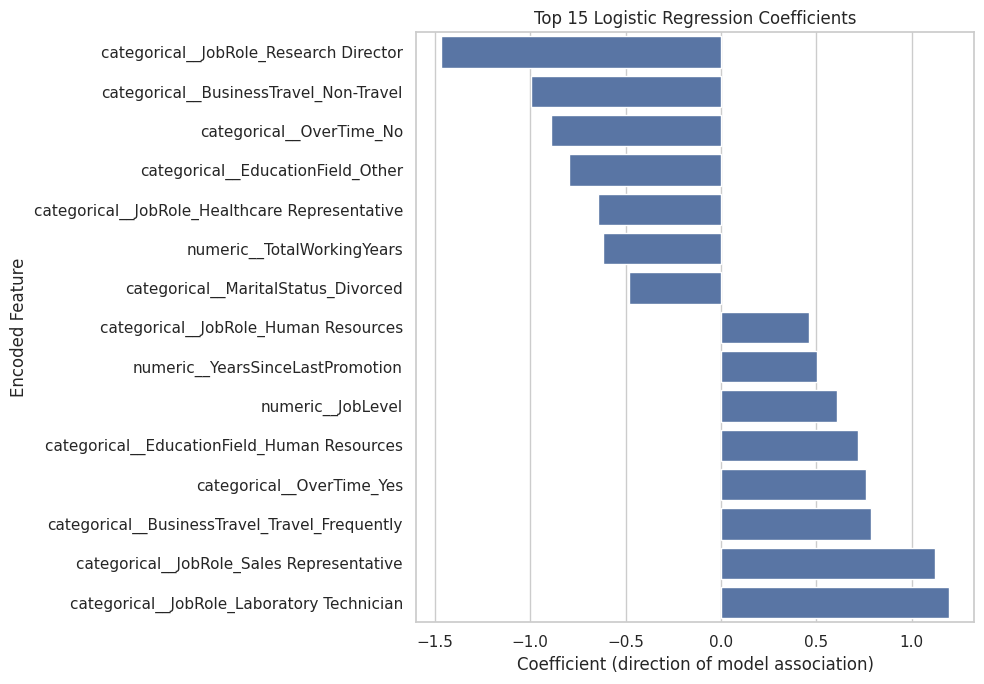

,Feature,Coefficient,AbsoluteCoefficient
42,categorical__JobRole_Research Director,-1.465683,1.465683
39,categorical__JobRole_Laboratory Technician,1.194333,1.194333
45,categorical__JobRole_Sales Representative,1.120617,1.120617
23,categorical__BusinessTravel_Non-Travel,-0.993885,0.993885
49,categorical__OverTime_No,-0.892809,0.892809
33,categorical__EducationField_Other,-0.798108,0.798108
24,categorical__BusinessTravel_Travel_Frequently,0.787566,0.787566
50,categorical__OverTime_Yes,0.761522,0.761522
29,categorical__EducationField_Human Resources,0.721129,0.721129
37,categorical__JobRole_Healthcare Representative,-0.647202,0.647202


In [11]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "classifier"
].coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["AbsoluteCoefficient"] = (
    importance["Coefficient"].abs()
)

importance = importance.sort_values(
    "AbsoluteCoefficient", ascending=False
)

top_features = importance.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)
plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient (direction of model association)")
plt.ylabel("Encoded Feature")
plt.tight_layout()
plt.savefig("week5_outputs/08_model_coefficients.png", dpi=300)
plt.show()

display(importance.head(15))
importance.to_csv(
    "week5_outputs/model_coefficients.csv",
    index=False
)

In [12]:
overall_attrition_rate = (
    (df["Attrition"] == "Yes").mean() * 100
)

highest_department = dept_rate.idxmax()
highest_department_rate = dept_rate.max()

highest_overtime_group = overtime_rate.idxmax()
highest_overtime_rate = overtime_rate.max()

summary_text = f"""
WEEK 5 DATA SCIENCE PROJECT SUMMARY
===================================

Dataset rows analyzed: {len(df)}
Dataset columns: {df.shape[1]}
Overall attrition rate: {overall_attrition_rate:.2f}%

Department with the highest observed attrition rate:
{highest_department} ({highest_department_rate:.2f}%)

Overtime group with the highest observed attrition rate:
{highest_overtime_group} ({highest_overtime_rate:.2f}%)

CHI-SQUARE TEST
---------------
Chi-square statistic: {chi2:.4f}
P-value: {p_value:.6f}

MACHINE LEARNING RESULTS
------------------------
{metrics_df.to_string(index=False)}

ROC-AUC: {auc_value:.4f}

Interpret results cautiously. These are patterns in a fictional
educational dataset and do not establish causation or describe
a current real-world workforce.
"""

print(summary_text)

with open(
    "week5_outputs/project_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(summary_text)


WEEK 5 DATA SCIENCE PROJECT SUMMARY

Dataset rows analyzed: 1470
Dataset columns: 35
Overall attrition rate: 16.12%

Department with the highest observed attrition rate:
Sales (20.63%)

Overtime group with the highest observed attrition rate:
Yes (30.53%)

CHI-SQUARE TEST
---------------
Chi-square statistic: 87.5643
P-value: 0.000000

MACHINE LEARNING RESULTS
------------------------
   Metric    Score
 Accuracy 0.751701
Precision 0.348837
   Recall 0.638298
 F1-score 0.451128
  ROC-AUC 0.803170

ROC-AUC: 0.8032

Interpret results cautiously. These are patterns in a fictional
educational dataset and do not establish causation or describe
a current real-world workforce.



In [13]:
# Save the analyzed data and summary tables
df.to_csv("week5_outputs/analyzed_hr_data.csv", index=False)
dept_rate.to_csv("week5_outputs/department_attrition_rates.csv")
overtime_rate.to_csv("week5_outputs/overtime_attrition_rates.csv")

# Bundle charts and output tables
with zipfile.ZipFile(
    "Week5_Project_Results.zip", "w", zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, filenames in os.walk("week5_outputs"):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zipf.write(full_path, arcname=full_path)

files.download("Week5_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>